# Compare All Models
Step-by-step analysis for human vs LLMs (8B/70B; zero/few).


In [ ]:
# Loader: human + model datasets with schema checks
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path('/home/ashrafs/projects/Conspiracy-Proj')
DATA = BASE / 'Data'
OUT = BASE / 'outputs'

# Human files
HUMAN_CLASS_CANDIDATES = [
    DATA / 'all_classifications.csv',
]
HUMAN_SPAN_CANDIDATES = [
    DATA / 'all_span_annotations.csv',
]

def first_existing(paths):
    for p in paths:
        if p.exists():
            return p
    return None

human_class_path = first_existing(HUMAN_CLASS_CANDIDATES)
human_span_path = first_existing(HUMAN_SPAN_CANDIDATES)

print('Human files:')
print(' - classification:', human_class_path)
print(' - spans:', human_span_path)

# Load human classifications
if human_class_path is None:
    agg = None
    print('WARNING: No human classification file found. Some analyses will be skipped.')
else:
    human_class = pd.read_csv(human_class_path)

    # Normalize booleans
    BOOL_MAP = {'true': True, 'false': False, 'yes': True, 'no': False, 'y': True, 'n': False, '1': True, '0': False}
    def parse_bool(s: pd.Series) -> pd.Series:
        v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
        unmapped = v.isna()
        if unmapped.any():
            num = pd.to_numeric(s[unmapped], errors='coerce')
            v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
        return v

    req_cols = {'text_id','conspiracy','supportive'}
    missing = req_cols - set(human_class.columns)
    if missing:
        print('WARNING: human_class missing columns:', missing)

    hc = human_class.copy()
    hc['conspiracy_mv'] = parse_bool(hc['conspiracy'])
    hc['supportive_mv'] = parse_bool(hc['supportive'])
    grp = hc.groupby('text_id', as_index=False)
    agg_core = grp.agg(
        conspiracy_mv=('conspiracy_mv', lambda x: bool(np.mean(x.dropna()) >= 0.5) if len(x.dropna()) else np.nan),
        supportive_mv=('supportive_mv', lambda x: bool(np.mean(x.dropna()) >= 0.5) if len(x.dropna()) else np.nan),
    )
    if 'annotator_id' in hc.columns:
        n_anns = grp['annotator_id'].nunique().rename(columns={'annotator_id':'n_annotators'})
        agg = agg_core.merge(n_anns, on='text_id', how='left')
    else:
        sizes = grp.size().rename(columns={'size':'n_annotators'})
        agg = agg_core.merge(sizes, on='text_id', how='left')
    print('Human majority-vote rows:', len(agg))

# Human spans presence
human_spans = None
if human_span_path and human_span_path.exists():
    human_spans = pd.read_csv(human_span_path)
    print('Human span columns:', [c for c in ['out-group','plan','call-to-action','in-group','secret'] if c in human_spans.columns])

# Model classification outputs (human-schema CSVs)
# Naming convention: {model_prefix}-{prompt_type}_all_classifications.csv
#   - model_prefix: llama8b (8B) or llama-3.3-70B (70B)
#   - prompt_type: zeroshot, fewshot, or frame
model_files = {
    '8b_zero': OUT / 'llama8b-zeroshot_all_classifications.csv',
    '8b_few': OUT / 'llama8b-fewshot_all_classifications.csv',
    '8b_frame': OUT / 'llama8b-frame_all_classifications.csv',
    '70b_zero': OUT / 'llama-3.3-70B-zeroshot_all_classifications.csv',
    '70b_few': OUT / 'llama-3.3-70B-fewshot_all_classifications.csv',
    '70b_frame': OUT / 'llama-3.3-70B-frame_all_classifications.csv',
}

experiments = {}
for name, path in model_files.items():
    df = pd.read_csv(path)
    # Mirror human-schema to generic
    BOOL_MAP = {'true': True, 'false': False, 'yes': True, 'no': False, 'y': True, 'n': False, '1': True, '0': False}
    def parse_bool_local(s: pd.Series) -> pd.Series:
        v = s.astype(str).str.strip().str.lower().map(BOOL_MAP)
        unmapped = v.isna()
        if unmapped.any():
            num = pd.to_numeric(s[unmapped], errors='coerce')
            v.loc[unmapped & num.notna()] = (num[num.notna()] > 0).astype(bool)
        return v
    if 'conspiracy' in df.columns:
        df['conspiracy'] = parse_bool_local(df['conspiracy'])
        df['is_conspiratorial'] = df['conspiracy']
    if 'supportive' in df.columns:
        df['supportive'] = parse_bool_local(df['supportive'])
        df['supports_conspiracy'] = df['supportive']
    experiments[name] = df
    print(f"Loaded {name}: {len(df):,} rows")

print('Ready: human agg and model dfs loaded')


Human files:
 - classification: /home/ashrafs/projects/Conspiracy-Proj/Data/all_classifications.csv
 - spans: /home/ashrafs/projects/Conspiracy-Proj/Data/all_span_annotations.csv
Human majority-vote rows: 2077
Human span columns: ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']
Loaded 8b_zero: 2,077 rows
Loaded 8b_few: 2,077 rows
Loaded 70b_zero: 2,077 rows
Loaded 70b_few: 2,077 rows
Ready: human agg and model dfs loaded


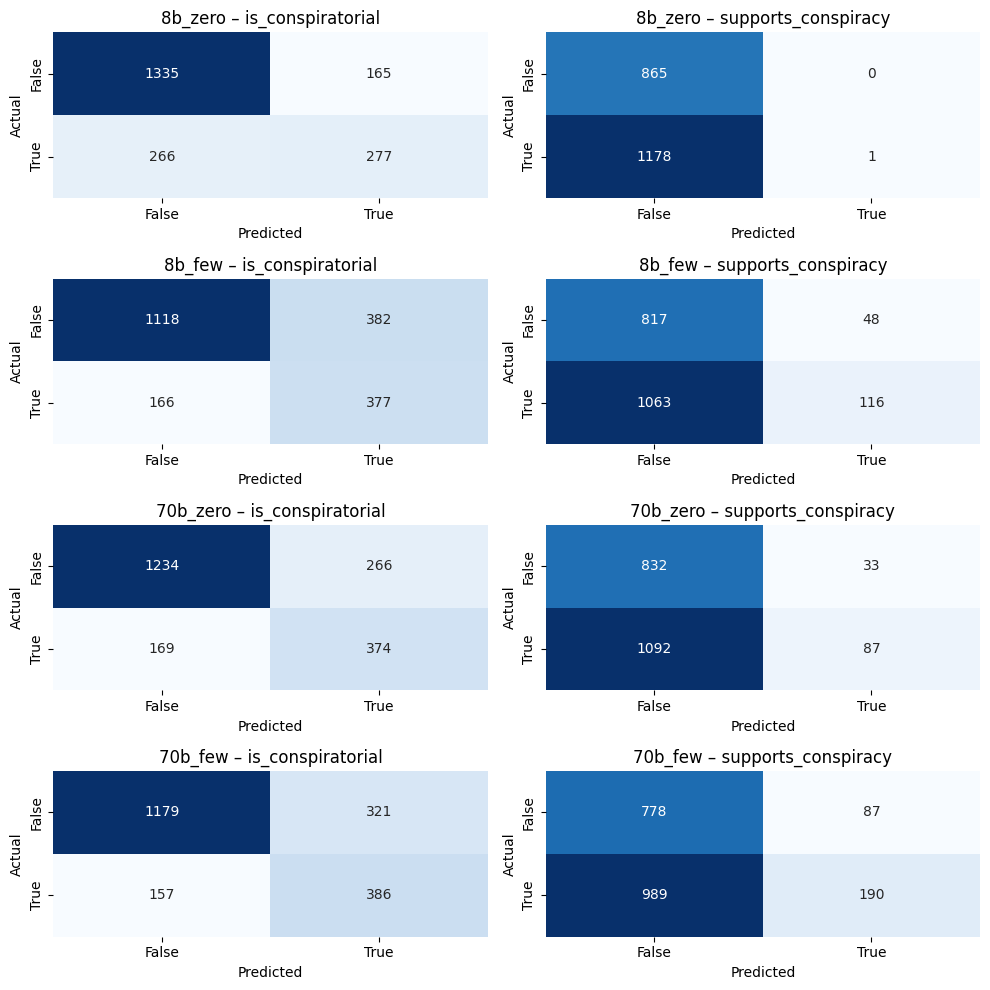

,experiment,task,accuracy,precision,recall,f1,n
6,70b_few,is_conspiratorial,0.766030,0.545969,0.710866,0.617600,2043
4,70b_zero,is_conspiratorial,0.787078,0.584375,0.688766,0.632291,2043
2,8b_few,is_conspiratorial,0.731767,0.496706,0.694291,0.579109,2043
0,8b_zero,is_conspiratorial,0.789036,0.626697,0.510129,0.562437,2043
7,70b_few,supports_conspiracy,0.473581,0.685921,0.161154,0.260989,2044
5,70b_zero,supports_conspiracy,0.449609,0.725000,0.073791,0.133949,2044
3,8b_few,supports_conspiracy,0.456458,0.707317,0.098388,0.172748,2044
1,8b_zero,supports_conspiracy,0.423679,1.000000,0.000848,0.001695,2044


In [ ]:
# Analysis 1: Confusion matrices and PRF (models vs human majority)
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

if 'agg' in globals() and agg is not None:
    results = []
    fig, axes = plt.subplots(len(experiments), 2, figsize=(10, 2+2*len(experiments)))
    if len(experiments)==1:
        axes = np.array([axes])
    row_idx = 0
    for exp_name, df in experiments.items():
        key = 'text_id'
        if key not in df.columns or key not in agg.columns:
            print(f'Skipping {exp_name}: missing text_id for join')
            continue
        merged = df[[key,'is_conspiratorial','supports_conspiracy']].merge(
            agg[[key,'conspiracy_mv','supportive_mv']], on=key, how='inner')
        for col_idx, (pred_col, human_col) in enumerate([('is_conspiratorial','conspiracy_mv'),('supports_conspiracy','supportive_mv')]):
            y_true = merged[human_col]
            y_pred = merged[pred_col]
            mask = y_true.notna() & y_pred.notna()
            y_true = y_true[mask].astype(bool)
            y_pred = y_pred[mask].astype(bool)
            if len(y_true)==0:
                ax = axes[row_idx, col_idx]
                sns.heatmap(np.zeros((2,2), dtype=int), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                            xticklabels=['False','True'], yticklabels=['False','True'])
                ax.set_title(f"{exp_name} – {pred_col}\n(no data)")
                continue
            cm = confusion_matrix(y_true, y_pred, labels=[False, True])
            acc = accuracy_score(y_true, y_pred)
            p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', zero_division=0)
            results.append({'experiment': exp_name, 'task': pred_col, 'accuracy': acc, 'precision': p, 'recall': r, 'f1': f1, 'n': int(len(y_true))})
            ax = axes[row_idx, col_idx]
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                        xticklabels=['False','True'], yticklabels=['False','True'])
            ax.set_title(f"{exp_name} – {pred_col}")
            ax.set_xlabel('Predicted')
            ax.set_ylabel('Actual')
        row_idx += 1
    plt.tight_layout(); plt.show()
    metrics_df = pd.DataFrame(results)
    if not metrics_df.empty and {'task','experiment'}.issubset(metrics_df.columns):
        display(metrics_df.sort_values(['task','experiment']))
    else:
        print('No metrics computed (empty).')
else:
    print('Human majority-vote labels not available; skipping confusion matrices.')


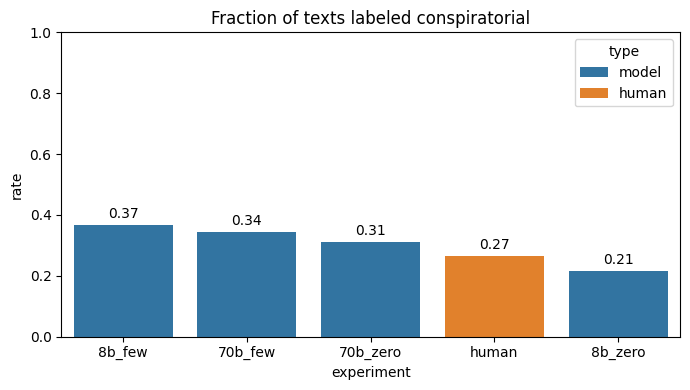

,experiment,type,n,n_true,rate
1,8b_few,model,2077,764,0.367838
3,70b_few,model,2077,712,0.342802
2,70b_zero,model,2077,645,0.310544
4,human,human,2043,543,0.265786
0,8b_zero,model,2077,445,0.214251


In [ ]:
# Analysis 2: Conspiratorial rate by experiment (incl. human)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

rows = []
for name, df in experiments.items():
    if 'is_conspiratorial' not in df.columns:
        continue
    pred = df['is_conspiratorial'].astype(bool)
    n = len(pred); n_true = int((pred==True).sum())
    rows.append({'experiment': name, 'type': 'model', 'n': n, 'n_true': n_true, 'rate': n_true/n if n else np.nan})

if 'agg' in globals() and agg is not None and 'conspiracy_mv' in agg.columns:
    h = agg['conspiracy_mv'].dropna().astype(bool)
    hn = len(h); hn_true = int((h==True).sum())
    rows.append({'experiment': 'human', 'type': 'human', 'n': hn, 'n_true': hn_true, 'rate': hn_true/hn if hn else np.nan})

rate_df = pd.DataFrame(rows).sort_values('rate', ascending=False)
plt.figure(figsize=(7,4))
ax = sns.barplot(data=rate_df, x='experiment', y='rate', hue='type', dodge=False, order=rate_df['experiment'])
plt.ylim(0,1); plt.title('Fraction of texts labeled conspiratorial')
for container in ax.containers:
    ax.bar_label(container, labels=[f"{bar.get_height():.2f}" for bar in container], padding=3)
plt.tight_layout(); plt.show()
rate_df


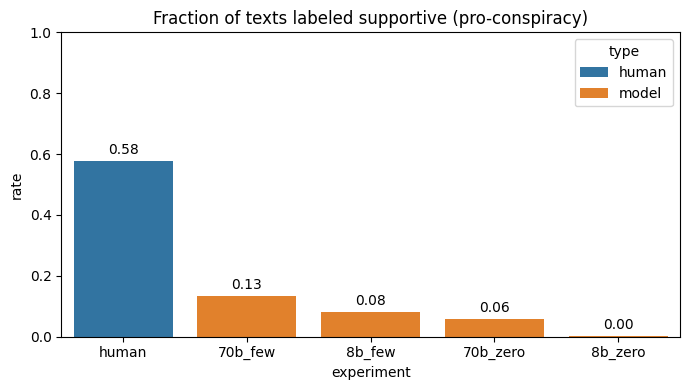

,experiment,type,n,n_true,rate
4,human,human,2044,1179,0.576810
3,70b_few,model,2077,279,0.134328
1,8b_few,model,2077,166,0.079923
2,70b_zero,model,2077,120,0.057776
0,8b_zero,model,2077,1,0.000481


In [ ]:
# Analysis 3: Supportive rate by experiment (incl. human)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

rows = []
for name, df in experiments.items():
    if 'supports_conspiracy' not in df.columns:
        continue
    pred = df['supports_conspiracy'].astype(bool)
    n = len(pred); n_true = int((pred==True).sum())
    rows.append({'experiment': name, 'type': 'model', 'n': n, 'n_true': n_true, 'rate': n_true/n if n else np.nan})

if 'agg' in globals() and agg is not None and 'supportive_mv' in agg.columns:
    h = agg['supportive_mv'].dropna().astype(bool)
    hn = len(h); hn_true = int((h==True).sum())
    rows.append({'experiment': 'human', 'type': 'human', 'n': hn, 'n_true': hn_true, 'rate': hn_true/hn if hn else np.nan})

supp_df = pd.DataFrame(rows).sort_values('rate', ascending=False)
plt.figure(figsize=(7,4))
ax = sns.barplot(data=supp_df, x='experiment', y='rate', hue='type', dodge=False, order=supp_df['experiment'])
plt.ylim(0,1); plt.title('Fraction of texts labeled supportive (pro-conspiracy)')
for container in ax.containers:
    ax.bar_label(container, labels=[f"{bar.get_height():.2f}" for bar in container], padding=3)
plt.tight_layout(); plt.show()
supp_df


Span presence summary:


,experiment,n_texts,rate_any,rate_out-group,rate_plan,rate_call-to-action,rate_in-group,rate_secret
0,8b_zero,2077,0.214251,0.147809,0.196919,0.066923,0.088108,0.178623
1,8b_few,2077,0.369764,0.326914,0.360616,0.037073,0.232547,0.061627
2,70b_zero,2077,0.391430,0.267212,0.322099,0.265768,0.132403,0.092922
3,70b_few,2077,0.362542,0.275397,0.341358,0.153587,0.172364,0.066923
4,human,934,0.980728,0.562099,0.841542,0.237687,0.543897,0.302998


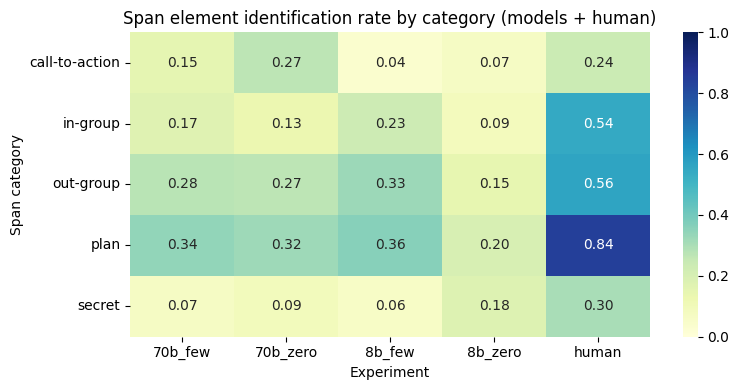

In [ ]:
# Analysis 4: Span element identification rates (models + human)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']

def is_present(col: pd.Series) -> pd.Series:
    s = col.astype(str).str.strip()
    sl = s.str.lower()
    return (
        col.notna() &
        s.ne('') &
        sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]')
    )

# Build span files for models by swapping suffix
span_files = {}
for name, class_path in model_files.items():
    span_path = Path(str(class_path).replace('_all_classifications.csv', '_all_span_annotations.csv'))
    span_files[name] = span_path

span_presence_rows = []
# Models
for name, spath in span_files.items():
    if not spath.exists():
        print(f"Missing span file for {name}: {spath}")
        continue
    df = pd.read_csv(spath)
    cols = [c for c in SPAN_COLS if c in df.columns]
    if not cols:
        print(f"No span category columns for {name}")
        continue
    pres = df[cols].apply(is_present)
    cat_rates = pres.mean().to_dict()
    any_present = pres.any(axis=1)
    span_presence_rows.append({
        'experiment': name,
        'n_texts': len(df),
        'rate_any': float(any_present.mean()),
        **{f'rate_{c}': float(cat_rates.get(c, np.nan)) for c in cols}
    })

# Human
if 'human_spans' in globals() and human_spans is not None:
    df = human_spans
    cols = [c for c in SPAN_COLS if c in df.columns]
    pres = df[cols].apply(is_present)
    cat_rates = pres.mean().to_dict()
    any_present = pres.any(axis=1)
    span_presence_rows.append({
        'experiment': 'human',
        'n_texts': len(df),
        'rate_any': float(any_present.mean()),
        **{f'rate_{c}': float(cat_rates.get(c, np.nan)) for c in cols}
    })

span_presence = pd.DataFrame(span_presence_rows)
print('Span presence summary:')
display(span_presence)

# Heatmap per category
if not span_presence.empty:
    long_rows = []
    for _, r in span_presence.iterrows():
        for c in SPAN_COLS:
            key = f'rate_{c}'
            if key in r and not pd.isna(r[key]):
                long_rows.append({'experiment': r['experiment'], 'category': c, 'rate': r[key]})
    if long_rows:
        long_df = pd.DataFrame(long_rows)
        pivot = long_df.pivot_table(index='category', columns='experiment', values='rate')
        plt.figure(figsize=(8,4))
        sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1)
        plt.title('Span element identification rate by category (models + human)')
        plt.xlabel('Experiment')
        plt.ylabel('Span category')
        plt.tight_layout(); plt.show()
    else:
        print('No per-category data to plot.')
else:
    print('No span presence data available.')


Unique text-level span presence summary:


,experiment,n_texts,rate_any,rate_out-group,rate_plan,rate_call-to-action,rate_in-group,rate_secret
0,8b_zero,2077,0.214251,0.147809,0.196919,0.066923,0.088108,0.178623
1,8b_few,2077,0.369764,0.326914,0.360616,0.037073,0.232547,0.061627
2,70b_zero,2077,0.391430,0.267212,0.322099,0.265768,0.132403,0.092922
3,70b_few,2077,0.362542,0.275397,0.341358,0.153587,0.172364,0.066923
4,human,755,0.984106,0.585430,0.876821,0.256954,0.585430,0.331126


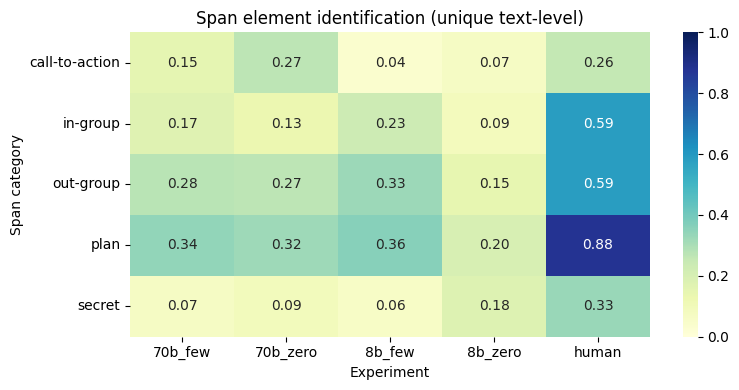

In [ ]:
# Analysis 4b: Span element identification (unique text-level presence)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']

def is_present(col: pd.Series) -> pd.Series:
    s = col.astype(str).str.strip()
    sl = s.str.lower()
    return (
        col.notna() & s.ne('') & sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]')
    )

# 1) Normalize HUMAN spans to one row per text_id: presence if ANY annotator marked it
human_unique = None
if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns:
    hs = human_spans.copy()
    cols = [c for c in SPAN_COLS if c in hs.columns]
    if cols:
        pres = hs[cols].apply(is_present)
        pres['text_id'] = hs['text_id']
        human_unique = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})

# 2) Normalize MODEL spans to one row per text_id (they should already be unique, but enforce)
span_files = {}
for name, class_path in model_files.items():
    span_path = Path(str(class_path).replace('_all_classifications.csv', '_all_span_annotations.csv'))
    span_files[name] = span_path

model_uniques = {}
for name, spath in span_files.items():
    if not spath.exists():
        continue
    df = pd.read_csv(spath)
    cols = [c for c in SPAN_COLS if c in df.columns]
    if not cols or 'text_id' not in df.columns:
        continue
    pres = df[cols].apply(is_present)
    pres['text_id'] = df['text_id']
    model_uniques[name] = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})

# 3) Compute rates across unique text_ids
rows = []
for name, pu in model_uniques.items():
    cols = [c for c in SPAN_COLS if c in pu.columns]
    if not cols:
        continue
    rates = pu[cols].mean().to_dict()
    any_present = pu[cols].any(axis=1)
    rows.append({'experiment': name, 'n_texts': len(pu), 'rate_any': float(any_present.mean()), **{f'rate_{c}': float(rates.get(c, np.nan)) for c in cols}})

if human_unique is not None:
    cols = [c for c in SPAN_COLS if c in human_unique.columns]
    rates = human_unique[cols].mean().to_dict()
    any_present = human_unique[cols].any(axis=1)
    rows.append({'experiment': 'human', 'n_texts': len(human_unique), 'rate_any': float(any_present.mean()), **{f'rate_{c}': float(rates.get(c, np.nan)) for c in cols}})

span_presence_unique = pd.DataFrame(rows)
print('Unique text-level span presence summary:')
display(span_presence_unique)

# Heatmap per category
if not span_presence_unique.empty:
    long_rows = []
    for _, r in span_presence_unique.iterrows():
        for c in SPAN_COLS:
            key = f'rate_{c}'
            if key in r and not pd.isna(r[key]):
                long_rows.append({'experiment': r['experiment'], 'category': c, 'rate': r[key]})
    if long_rows:
        long_df = pd.DataFrame(long_rows)
        pivot = long_df.pivot_table(index='category', columns='experiment', values='rate')
        plt.figure(figsize=(8,4))
        sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1)
        plt.title('Span element identification (unique text-level)')
        plt.xlabel('Experiment')
        plt.ylabel('Span category')
        plt.tight_layout(); plt.show()
    else:
        print('No per-category data to plot.')
else:
    print('No span presence data available.')


Any-span presence by conspiracy label:


,experiment,label,n,rate_any
0,human,conspiracy=False,213,0.953052
1,human,conspiracy=True,534,0.996255
2,8b_zero,conspiracy=False,1632,0.000000
3,8b_zero,conspiracy=True,445,1.000000
4,8b_few,conspiracy=False,1313,0.003046
5,8b_few,conspiracy=True,764,1.000000
6,70b_zero,conspiracy=False,1432,0.117318
7,70b_zero,conspiracy=True,645,1.000000
8,70b_few,conspiracy=False,1365,0.030037
9,70b_few,conspiracy=True,712,1.000000


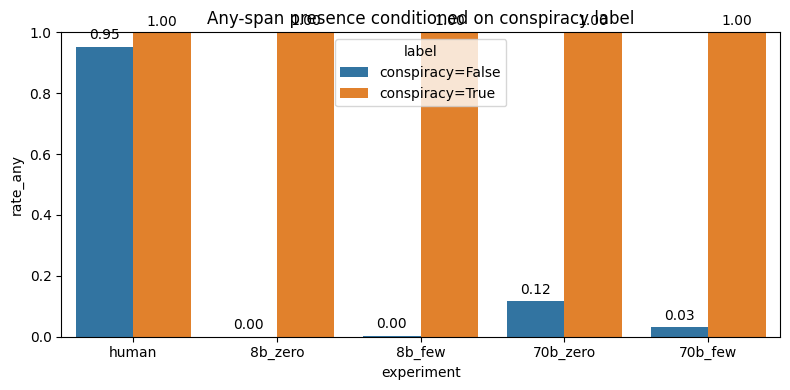

In [ ]:
# Analysis 5: Any-span presence conditioned on conspiracy label (human vs models)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']

def is_present(col: pd.Series) -> pd.Series:
    s = col.astype(str).str.strip()
    sl = s.str.lower()
    return (col.notna() & s.ne('') & sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]'))

# Build unique human span presence per text_id
human_unique = None
if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns:
    hs = human_spans.copy()
    cols = [c for c in SPAN_COLS if c in hs.columns]
    if cols:
        pres = hs[cols].apply(is_present)
        pres['text_id'] = hs['text_id']
        human_unique = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
        human_unique['any_span'] = human_unique[cols].any(axis=1)

rows = []
# Human: join with majority-vote conspiracy
if human_unique is not None and 'agg' in globals() and agg is not None:
    hjoin = human_unique.merge(agg[['text_id','conspiracy_mv']], on='text_id', how='inner')
    for val, sub in hjoin.groupby('conspiracy_mv'):
        if len(sub) == 0:
            continue
        rows.append({'experiment':'human', 'label':'conspiracy='+str(bool(val)), 'n':len(sub), 'rate_any': float(sub['any_span'].mean())})

# Models: unique span presence per text_id + model conspiracy prediction
span_files = {name: Path(str(path).replace('_all_classifications.csv', '_all_span_annotations.csv')) for name, path in model_files.items()}
for name, spath in span_files.items():
    if not spath.exists() or name not in experiments:
        continue
    sdf = pd.read_csv(spath)
    cols = [c for c in SPAN_COLS if c in sdf.columns]
    if not cols or 'text_id' not in sdf.columns:
        continue
    pres = sdf[cols].apply(is_present)
    pres['text_id'] = sdf['text_id']
    uniq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
    uniq['any_span'] = uniq[cols].any(axis=1)
    clf = experiments[name][['text_id','is_conspiratorial']].dropna().drop_duplicates('text_id')
    j = uniq.merge(clf, on='text_id', how='inner')
    for val, sub in j.groupby('is_conspiratorial'):
        if len(sub)==0:
            continue
        rows.append({'experiment':name, 'label':'conspiracy='+str(bool(val)), 'n':len(sub), 'rate_any': float(sub['any_span'].mean())})

cond_df = pd.DataFrame(rows)
print('Any-span presence by conspiracy label:')
display(cond_df)

# Plot
if not cond_df.empty:
    plt.figure(figsize=(8,4))
    ax = sns.barplot(data=cond_df, x='experiment', y='rate_any', hue='label')
    plt.ylim(0,1)
    plt.title('Any-span presence conditioned on conspiracy label')
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{bar.get_height():.2f}" for bar in container], padding=3)
    plt.tight_layout(); plt.show()
else:
    print('No data to plot.')


Any-span presence by supportive label:


,experiment,label,n,rate_any
0,human,supportive=False,124,0.991935
1,human,supportive=True,625,0.982400
2,8b_zero,supportive=False,2076,0.214355
3,8b_zero,supportive=True,1,0.000000
4,8b_few,supportive=False,1911,0.400837
5,8b_few,supportive=True,166,0.012048
6,70b_zero,supportive=False,1957,0.369443
7,70b_zero,supportive=True,120,0.750000
8,70b_few,supportive=False,1798,0.407119
9,70b_few,supportive=True,279,0.075269


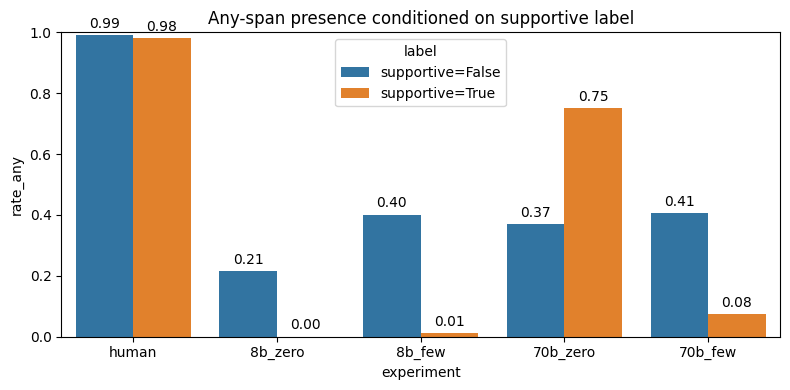

In [ ]:
# Analysis 6: Any-span presence conditioned on supportive label (human vs models)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']

def is_present(col: pd.Series) -> pd.Series:
    s = col.astype(str).str.strip(); sl = s.str.lower()
    return (col.notna() & s.ne('') & sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]'))

# Unique human spans per text_id
human_unique = None
if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns:
    hs = human_spans.copy(); cols = [c for c in SPAN_COLS if c in hs.columns]
    if cols:
        pres = hs[cols].apply(is_present); pres['text_id'] = hs['text_id']
        human_unique = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
        human_unique['any_span'] = human_unique[cols].any(axis=1)

rows = []
# Human: join with majority-vote supportive
if human_unique is not None and 'agg' in globals() and agg is not None and 'supportive_mv' in agg.columns:
    hjoin = human_unique.merge(agg[['text_id','supportive_mv']], on='text_id', how='inner')
    for val, sub in hjoin.groupby('supportive_mv'):
        if len(sub):
            rows.append({'experiment':'human', 'label':'supportive='+str(bool(val)), 'n':len(sub), 'rate_any': float(sub['any_span'].mean())})

# Models: unique span presence + model supportive prediction
span_files = {name: Path(str(path).replace('_all_classifications.csv', '_all_span_annotations.csv')) for name, path in model_files.items()}
for name, spath in span_files.items():
    if not spath.exists() or name not in experiments:
        continue
    sdf = pd.read_csv(spath); cols = [c for c in SPAN_COLS if c in sdf.columns]
    if not cols or 'text_id' not in sdf.columns:
        continue
    pres = sdf[cols].apply(is_present); pres['text_id'] = sdf['text_id']
    uniq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols}); uniq['any_span'] = uniq[cols].any(axis=1)
    clf = experiments[name][['text_id','supports_conspiracy']].dropna().drop_duplicates('text_id')
    j = uniq.merge(clf, on='text_id', how='inner')
    for val, sub in j.groupby('supports_conspiracy'):
        if len(sub):
            rows.append({'experiment':name, 'label':'supportive='+str(bool(val)), 'n':len(sub), 'rate_any': float(sub['any_span'].mean())})

supportive_cond_df = pd.DataFrame(rows)
print('Any-span presence by supportive label:')
display(supportive_cond_df)

if not supportive_cond_df.empty:
    plt.figure(figsize=(8,4))
    ax = sns.barplot(data=supportive_cond_df, x='experiment', y='rate_any', hue='label')
    plt.ylim(0,1); plt.title('Any-span presence conditioned on supportive label')
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{bar.get_height():.2f}" for bar in container], padding=3)
    plt.tight_layout(); plt.show()
else:
    print('No data to plot.')


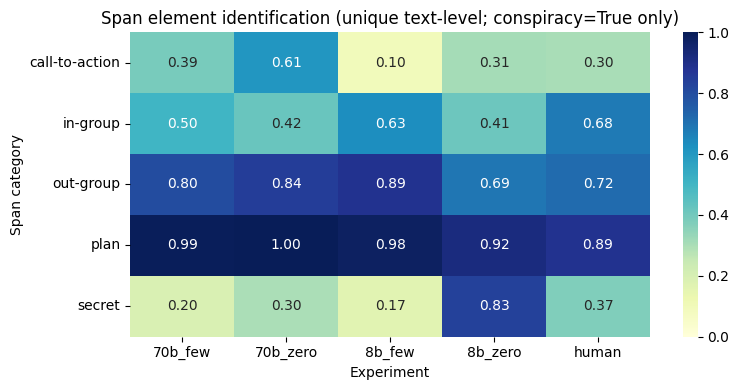

,experiment,rate_out-group,rate_plan,rate_call-to-action,rate_in-group,rate_secret
0,human,0.715356,0.885768,0.301498,0.681648,0.374532
1,8b_zero,0.689888,0.919101,0.312360,0.411236,0.833708
2,8b_few,0.886126,0.980366,0.095550,0.632199,0.167539
3,70b_zero,0.844961,0.998450,0.606202,0.418605,0.297674
4,70b_few,0.803371,0.994382,0.390449,0.501404,0.195225


In [32]:
# Analysis 7: Span element identification (unique text-level) restricted to conspiracy = True
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']

def is_present(col: pd.Series) -> pd.Series:
    s = col.astype(str).str.strip(); sl = s.str.lower()
    return (col.notna() & s.ne('') & sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]'))

rows = []

# Human: unique spans per text_id, filter conspiracy_mv=True
human_unique = None
if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns and 'agg' in globals() and agg is not None:
    hs = human_spans.copy(); cols = [c for c in SPAN_COLS if c in hs.columns]
    if cols:
        pres = hs[cols].apply(is_present); pres['text_id'] = hs['text_id']
        hunq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
        hunq['any_span'] = hunq[cols].any(axis=1)
        hjoin = hunq.merge(agg[['text_id','conspiracy_mv']], on='text_id', how='inner')
        htrue = hjoin[hjoin['conspiracy_mv'] == True]
        if not htrue.empty:
            rates = htrue[cols].mean().to_dict()
            rows.append({'experiment':'human', **{f'rate_{c}': float(rates.get(c, np.nan)) for c in cols}})

# Models: unique spans per text_id, filter is_conspiratorial=True
span_files = {name: Path(str(path).replace('_all_classifications.csv', '_all_span_annotations.csv')) for name, path in model_files.items()}
for name, spath in span_files.items():
    if not spath.exists() or name not in experiments:
        continue
    sdf = pd.read_csv(spath); cols = [c for c in SPAN_COLS if c in sdf.columns]
    if not cols or 'text_id' not in sdf.columns:
        continue
    pres = sdf[cols].apply(is_present); pres['text_id'] = sdf['text_id']
    munq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
    j = munq.merge(experiments[name][['text_id','is_conspiratorial']].drop_duplicates('text_id'), on='text_id', how='inner')
    jtrue = j[j['is_conspiratorial'] == True]
    if not jtrue.empty:
        rates = jtrue[cols].mean().to_dict()
        rows.append({'experiment':name, **{f'rate_{c}': float(rates.get(c, np.nan)) for c in cols}})

# Build heatmap
if rows:
    df = pd.DataFrame(rows)
    long_rows = []
    for _, r in df.iterrows():
        for c in SPAN_COLS:
            key = f'rate_{c}'
            if key in r and not pd.isna(r[key]):
                long_rows.append({'experiment': r['experiment'], 'category': c, 'rate': r[key]})
    long_df = pd.DataFrame(long_rows)
    pivot = long_df.pivot_table(index='category', columns='experiment', values='rate')
    plt.figure(figsize=(8,4))
    sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1)
    plt.title('Span element identification (unique text-level; conspiracy=True only)')
    plt.xlabel('Experiment')
    plt.ylabel('Span category')
    plt.tight_layout(); plt.show()
    display(df)
else:
    print('No data available for conspiracy=True filter.')


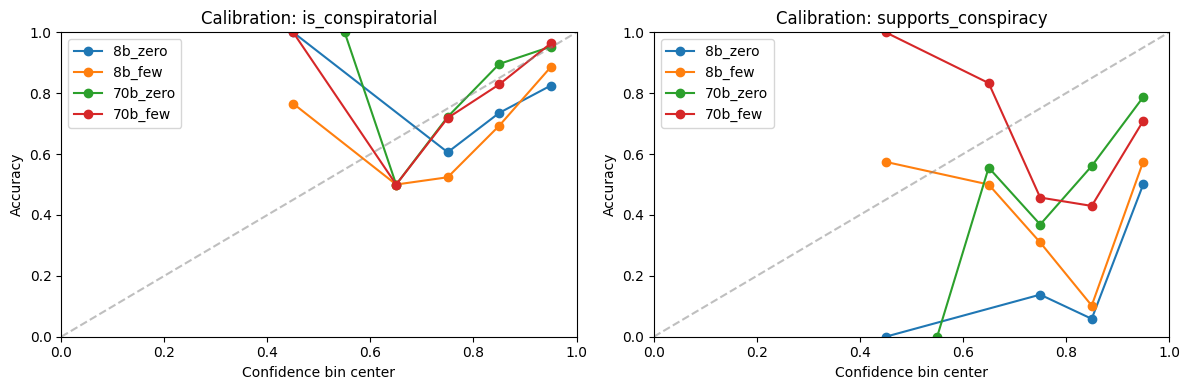

task,is_conspiratorial,supports_conspiracy
experiment,,
70b_few,0.077,0.369
70b_zero,0.057,0.391
8b_few,0.187,0.459
8b_zero,0.179,0.539


In [40]:
# Analysis 8b: Reliability diagrams using model confidences from outputs/*_all_classifications.csv (skip human)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

bins = np.linspace(0,1,11)

# Build a view per model with prediction + confidence from outputs/*_all_classifications.csv
model_view = {}
for name, class_path in model_files.items():
    p = Path(class_path)
    if not p.exists():
        continue
    df = pd.read_csv(p)
    # Expect human-schema columns: conspiracy/supportive/confidence
    if not {'text_id','conspiracy','supportive','confidence'} <= set(df.columns):
        continue
    mv = df[['text_id','conspiracy','supportive','confidence']].copy()
    mv['is_conspiratorial'] = mv['conspiracy'].astype(str).str.lower().map({'true':True,'false':False,'yes':True,'no':False,'1':True,'0':False})
    mv['supports_conspiracy'] = mv['supportive'].astype(str).str.lower().map({'true':True,'false':False,'yes':True,'no':False,'1':True,'0':False})
    mv['llm_confidence'] = pd.to_numeric(mv['confidence'], errors='coerce').clip(0,1)
    model_view[name] = mv.drop(columns=['conspiracy','supportive','confidence'])

# Plot two-panel reliability and ECE per model (truth from human MV if available)
fig, axes = plt.subplots(1,2, figsize=(12,4))
results = []
for ax_idx, (task, mv_col) in enumerate([('is_conspiratorial','conspiracy_mv'),('supports_conspiracy','supportive_mv')]):
    ax = axes[ax_idx]
    for name, mv in model_view.items():
        if task not in mv.columns or 'llm_confidence' not in mv.columns:
            continue
        # Join human MV for ground truth
        if 'agg' in globals() and agg is not None and mv_col in agg.columns:
            j = mv.merge(agg[['text_id', mv_col]], on='text_id', how='inner')
            if j.empty:
                continue
            conf = pd.to_numeric(j['llm_confidence'], errors='coerce').clip(0,1)
            pred = j[task].astype(bool)
            true = j[mv_col].astype(bool)
        else:
            continue
        m = conf.notna() & pred.notna() & true.notna()
        conf, pred, true = conf[m], pred[m], true[m]
        if len(conf)==0:
            continue
        # ECE
        bin_ids = np.digitize(conf, bins, right=True)
        correct = (pred==true).astype(float).values
        ece = 0.0
        n = len(conf)
        xs, ys = [], []
        for b in range(1, len(bins)):
            sel = bin_ids == b
            if sel.sum()==0: continue
            xs.append((bins[b-1]+bins[b])/2)
            acc = (pred[sel]==true[sel]).mean()
            ys.append(acc)
            avg_conf = conf[sel].mean()
            ece += (sel.sum()/n) * abs(acc - avg_conf)
        results.append({'experiment': name, 'task': task, 'ece': float(ece), 'n': int(n)})
        ax.plot(xs, ys, marker='o', label=name)
    ax.plot([0,1],[0,1],'--',color='gray',alpha=0.5)
    ax.set_title(f'Calibration: {task}')
    ax.set_xlabel('Confidence bin center')
    ax.set_ylabel('Accuracy')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.legend()
plt.tight_layout(); plt.show()

if results:
    ece_df = pd.DataFrame(results)
    display(ece_df.pivot_table(index='experiment', columns='task', values='ece').round(3))
else:
    print('No ECE data available (check confidences in outputs/*_all_classifications.csv).')


Missing span annotations among conspiracy=True cases:


,experiment,missing_pct,n
0,human,0.003745,534
1,8b_zero,0.000000,445
2,8b_few,0.000000,764
3,70b_zero,0.000000,645
4,70b_few,0.000000,712


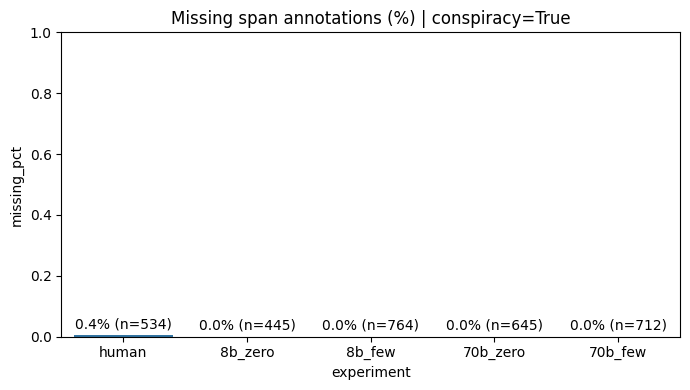

In [41]:
# Analysis 9: Missing span annotations (%) for conspiracy=True cases (human vs models)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

SPAN_COLS = ['out-group','plan','call-to-action','in-group','secret']

def is_present(col: pd.Series) -> pd.Series:
    s = col.astype(str).str.strip(); sl = s.str.lower()
    return (col.notna() & s.ne('') & sl.ne('nan') & sl.ne('none') & sl.ne('null') & sl.ne('[]'))

bars = []
# Human: conspiracy_mv=True
if 'agg' in globals() and agg is not None and 'conspiracy_mv' in agg.columns:
    # unique human spans per text_id
    human_unique = None
    if 'human_spans' in globals() and human_spans is not None and 'text_id' in human_spans.columns:
        hs = human_spans.copy(); cols = [c for c in SPAN_COLS if c in hs.columns]
        if cols:
            pres = hs[cols].apply(is_present); pres['text_id'] = hs['text_id']
            human_unique = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
            human_unique['any_span'] = human_unique[cols].any(axis=1)
    if human_unique is not None:
        hjoin = human_unique.merge(agg[['text_id','conspiracy_mv']], on='text_id', how='inner')
        cons = hjoin[hjoin['conspiracy_mv']==True]
        if not cons.empty:
            missing_pct = float((~cons['any_span']).mean())
            bars.append({'experiment':'human','missing_pct': missing_pct, 'n': int(len(cons))})

# Models: conspiracy=True by each model's prediction
span_files = {name: Path(str(path).replace('_all_classifications.csv', '_all_span_annotations.csv')) for name, path in model_files.items()}
for name, spath in span_files.items():
    if not spath.exists() or name not in experiments:
        continue
    sdf = pd.read_csv(spath)
    cols = [c for c in SPAN_COLS if c in sdf.columns]
    if not cols or 'text_id' not in sdf.columns:
        continue
    pres = sdf[cols].apply(is_present); pres['text_id'] = sdf['text_id']
    munq = pres.groupby('text_id', as_index=False).agg({c: 'any' for c in cols})
    munq['any_span'] = munq[cols].any(axis=1)
    clf = experiments[name][['text_id','is_conspiratorial']].drop_duplicates('text_id')
    j = munq.merge(clf, on='text_id', how='inner')
    cons = j[j['is_conspiratorial']==True]
    if not cons.empty:
        missing_pct = float((~cons['any_span']).mean())
        bars.append({'experiment': name, 'missing_pct': missing_pct, 'n': int(len(cons))})

miss_df = pd.DataFrame(bars)
print('Missing span annotations among conspiracy=True cases:')
display(miss_df)

if not miss_df.empty:
    plt.figure(figsize=(7,4))
    ax = sns.barplot(data=miss_df, x='experiment', y='missing_pct')
    plt.ylim(0,1)
    plt.title('Missing span annotations (%) | conspiracy=True')
    ax.bar_label(ax.containers[0], labels=[f"{v*100:.1f}% (n={n})" for v,n in zip(miss_df['missing_pct'], miss_df['n'])], padding=3)
    plt.tight_layout(); plt.show()
else:
    print('No data available for plotting.')


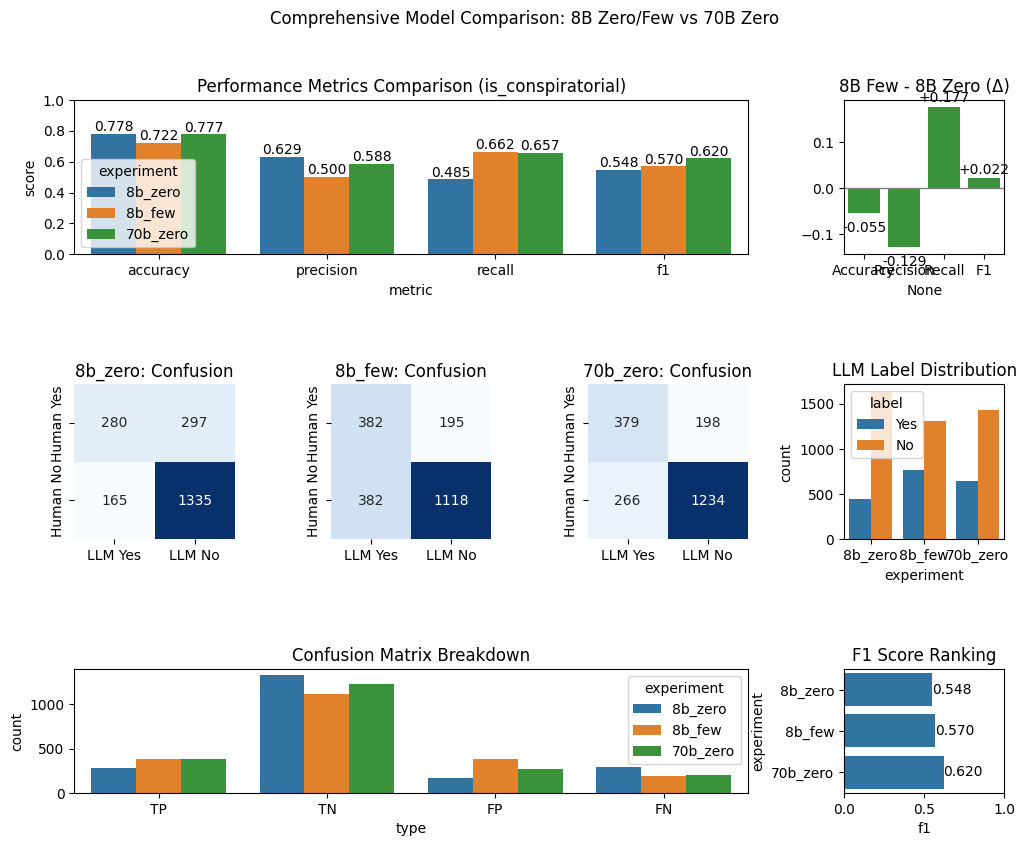

In [42]:
# Analysis 10: Comprehensive dashboard (metrics, confusion, distributions, ranking)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import gridspec

# Choose three experiments to showcase side-by-side
order = ['8b_zero','8b_few','70b_zero']
exps = [e for e in order if e in experiments]
if len(exps) < 2:
    print('Not enough experiments to plot.');
else:
    # Build joined frames with human MV for confusion matrices/metrics
    joins = {}
    for name in exps:
        df = experiments[name]
        if not {'text_id','is_conspiratorial','supports_conspiracy'} <= set(df.columns):
            continue
        if 'agg' in globals() and agg is not None:
            j = df[['text_id','is_conspiratorial','supports_conspiracy']].merge(
                agg[['text_id','conspiracy_mv','supportive_mv']], on='text_id', how='inner')
            if len(j)>0:
                joins[name] = j

    # Compute metrics
    rows = []
    cms = {}
    for name, j in joins.items():
        for task, mv in [('is_conspiratorial','conspiracy_mv'),('supports_conspiracy','supportive_mv')]:
            y_true = j[mv].astype(bool)
            y_pred = j[task].astype(bool)
            tp = int(((y_true==1)&(y_pred==1)).sum())
            tn = int(((y_true==0)&(y_pred==0)).sum())
            fp = int(((y_true==0)&(y_pred==1)).sum())
            fn = int(((y_true==1)&(y_pred==0)).sum())
            acc = (tp+tn)/(tp+tn+fp+fn)
            prec = tp/ (tp+fp) if (tp+fp)>0 else 0.0
            rec = tp/ (tp+fn) if (tp+fn)>0 else 0.0
            f1 = (2*prec*rec)/(prec+rec) if (prec+rec)>0 else 0.0
            rows.append({'experiment':name,'task':task,'accuracy':acc,'precision':prec,'recall':rec,'f1':f1,'tp':tp,'tn':tn,'fp':fp,'fn':fn})
            if task=='is_conspiratorial':
                cms[name] = np.array([[tp, fn],[fp, tn]]) # arranged for annotation later

    met = pd.DataFrame(rows)
    if met.empty:
        print('No metrics computed.');
    else:
        # Figure layout
        plt.figure(figsize=(12,9))
        gs = gridspec.GridSpec(3,4, height_ratios=[2,2,1.6], width_ratios=[1,1,1,1], wspace=0.6, hspace=0.9)

        # 1) Metrics bars (top-left spanning two columns)
        ax1 = plt.subplot(gs[0, :3])
        sel = met[met['task']=='is_conspiratorial'][['experiment','accuracy','precision','recall','f1']]
        mlong = sel.melt(id_vars='experiment', var_name='metric', value_name='score')
        sns.barplot(data=mlong, x='metric', y='score', hue='experiment', ax=ax1)
        ax1.set_ylim(0,1); ax1.set_title('Performance Metrics Comparison (is_conspiratorial)')
        for c in ax1.containers:
            ax1.bar_label(c, fmt='%.3f')

        # 2) Improvement bars (few-shot vs zero-shot if both present)
        ax2 = plt.subplot(gs[0, 3])
        if set(['8b_zero','8b_few']).issubset(set(exps)):
            a = met[(met['experiment']=='8b_zero')&(met['task']=='is_conspiratorial')].iloc[0]
            b = met[(met['experiment']=='8b_few')&(met['task']=='is_conspiratorial')].iloc[0]
            diff = pd.Series({
                'Accuracy': b['accuracy']-a['accuracy'],
                'Precision': b['precision']-a['precision'],
                'Recall': b['recall']-a['recall'],
                'F1': b['f1']-a['f1']
            })
            sns.barplot(x=diff.index, y=diff.values, ax=ax2, color='tab:green')
            ax2.set_title('8B Few - 8B Zero (Δ)'); ax2.axhline(0,color='gray',lw=1)
            for i,v in enumerate(diff.values):
                ax2.text(i, v+(0.01 if v>=0 else -0.04), f'{v:+.3f}', ha='center')
        else:
            ax2.text(0.5,0.5,'Δ requires 8b_zero & 8b_few',ha='center',va='center'); ax2.set_xticks([]); ax2.set_yticks([])

        # 3) Confusion matrices (row 2)
        for i,name in enumerate(exps[:3]):
            ax = plt.subplot(gs[1, i])
            if name in cms:
                tp, fn = cms[name][0]
                fp, tn = cms[name][1]
                data = np.array([[tp, fn],[fp, tn]])
                sns.heatmap(data, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                            xticklabels=['LLM Yes','LLM No'], yticklabels=['Human Yes','Human No'])
                ax.set_title(f'{name}: Confusion')
            else:
                ax.text(0.5,0.5,'No data',ha='center',va='center'); ax.set_xticks([]); ax.set_yticks([])

        # 4) Label distribution (row 2, col 3)
        ax = plt.subplot(gs[1, 3])
        counts = []
        for name in exps:
            j = joins.get(name)
            if j is None: continue
            counts.append({'experiment':name,'label':'Yes','count': int(j['is_conspiratorial'].sum())})
            counts.append({'experiment':name,'label':'No','count': int((~j['is_conspiratorial']).sum())})
        if counts:
            dfc = pd.DataFrame(counts)
            sns.barplot(data=dfc, x='experiment', y='count', hue='label', ax=ax)
            ax.set_title('LLM Label Distribution')
        else:
            ax.text(0.5,0.5,'No data',ha='center',va='center'); ax.set_xticks([]); ax.set_yticks([])

        # 5) F1 ranking (row 3, col 3)
        ax = plt.subplot(gs[2, 3])
        f1s = met[met['task']=='is_conspiratorial'][['experiment','f1']].sort_values('f1')
        sns.barplot(data=f1s, x='f1', y='experiment', ax=ax)
        ax.set_xlim(0,1); ax.set_title('F1 Score Ranking')
        for c in ax.containers:
            ax.bar_label(c, fmt='%.3f')

        # 6) Confusion breakdown (row 3, span first three cols)
        ax = plt.subplot(gs[2, :3])
        parts = []
        for name in exps:
            j = joins.get(name);
            if j is None: continue
            y_true = j['conspiracy_mv'].astype(bool); y_pred = j['is_conspiratorial'].astype(bool)
            parts.extend([
                {'experiment':name,'type':'TP','count': int(((y_true==1)&(y_pred==1)).sum())},
                {'experiment':name,'type':'TN','count': int(((y_true==0)&(y_pred==0)).sum())},
                {'experiment':name,'type':'FP','count': int(((y_true==0)&(y_pred==1)).sum())},
                {'experiment':name,'type':'FN','count': int(((y_true==1)&(y_pred==0)).sum())},
            ])
        if parts:
            dfp = pd.DataFrame(parts)
            sns.barplot(data=dfp, x='type', y='count', hue='experiment', ax=ax)
            ax.set_title('Confusion Matrix Breakdown')
        else:
            ax.text(0.5,0.5,'No data',ha='center',va='center'); ax.set_xticks([]); ax.set_yticks([])

        plt.suptitle('Comprehensive Model Comparison: 8B Zero/Few vs 70B Zero', y=0.98, fontsize=12)
        plt.show()



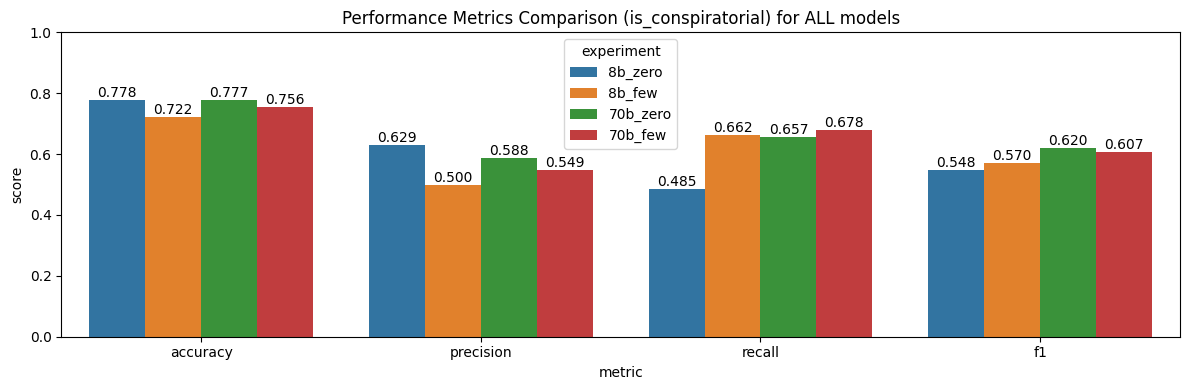

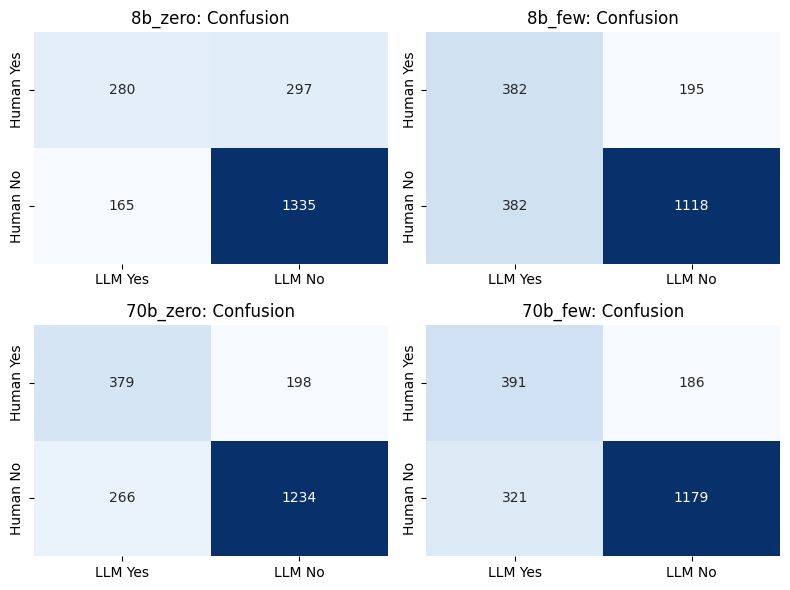

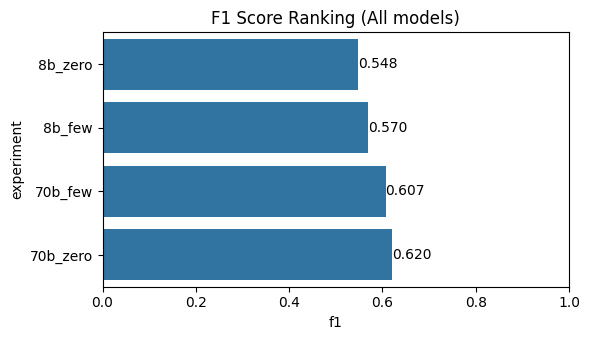

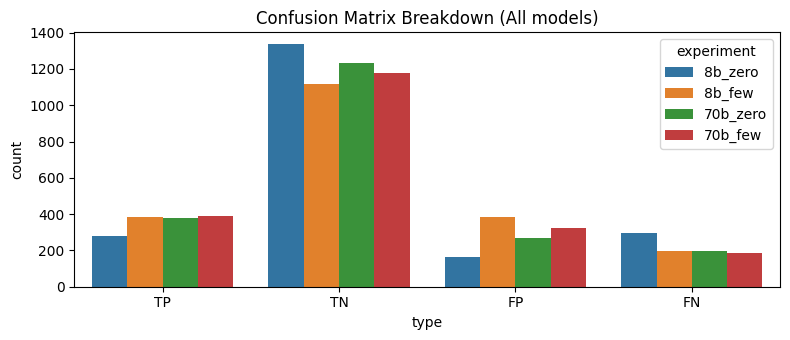

In [43]:
# Analysis 10b: Comprehensive dashboard for ALL available models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Determine experiments available
exps = [name for name in experiments.keys()]
if len(exps) < 2:
    print('Not enough experiments to plot.')
else:
    # Join with human MV
    joins = {}
    for name in exps:
        df = experiments[name]
        if not {'text_id','is_conspiratorial','supports_conspiracy'} <= set(df.columns):
            continue
        if 'agg' in globals() and agg is not None:
            j = df[['text_id','is_conspiratorial','supports_conspiracy']].merge(
                agg[['text_id','conspiracy_mv','supportive_mv']], on='text_id', how='inner')
            if len(j)>0:
                joins[name] = j

    # Metrics and confusions
    rows = []
    cms = {}
    for name, j in joins.items():
        y_true = j['conspiracy_mv'].astype(bool)
        y_pred = j['is_conspiratorial'].astype(bool)
        tp = int(((y_true==1)&(y_pred==1)).sum())
        tn = int(((y_true==0)&(y_pred==0)).sum())
        fp = int(((y_true==0)&(y_pred==1)).sum())
        fn = int(((y_true==1)&(y_pred==0)).sum())
        acc = (tp+tn)/(tp+tn+fp+fn)
        prec = tp/(tp+fp) if (tp+fp)>0 else 0.0
        rec = tp/(tp+fn) if (tp+fn)>0 else 0.0
        f1 = (2*prec*rec)/(prec+rec) if (prec+rec)>0 else 0.0
        rows.append({'experiment':name,'accuracy':acc,'precision':prec,'recall':rec,'f1':f1,'tp':tp,'tn':tn,'fp':fp,'fn':fn})
        cms[name] = np.array([[tp, fn],[fp, tn]])

    met = pd.DataFrame(rows)
    if met.empty:
        print('No metrics computed.')
    else:
        # 1) Metrics comparison
        plt.figure(figsize=(12,4))
        mlong = met.melt(id_vars='experiment', value_vars=['accuracy','precision','recall','f1'], var_name='metric', value_name='score')
        sns.barplot(data=mlong, x='metric', y='score', hue='experiment')
        plt.ylim(0,1); plt.title('Performance Metrics Comparison (is_conspiratorial) for ALL models')
        for c in plt.gca().containers:
            plt.gca().bar_label(c, fmt='%.3f')
        plt.tight_layout(); plt.show()

        # 2) Confusion matrices grid
        n = len(joins)
        cols = 2
        rows_g = math.ceil(n/cols)
        fig, axes = plt.subplots(rows_g, cols, figsize=(8, 3*rows_g))
        axes = np.array(axes).reshape(rows_g, cols)
        i = 0
        for r in range(rows_g):
            for c in range(cols):
                ax = axes[r,c]
                if i >= n:
                    ax.axis('off'); continue
                name = list(joins.keys())[i]
                tp, fn = cms[name][0]
                fp, tn = cms[name][1]
                data = np.array([[tp, fn],[fp, tn]])
                sns.heatmap(data, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                            xticklabels=['LLM Yes','LLM No'], yticklabels=['Human Yes','Human No'])
                ax.set_title(f'{name}: Confusion')
                i += 1
        fig.tight_layout(); plt.show()

        # 3) F1 ranking
        plt.figure(figsize=(6,3.5))
        f1s = met[['experiment','f1']].sort_values('f1')
        sns.barplot(data=f1s, x='f1', y='experiment')
        plt.xlim(0,1); plt.title('F1 Score Ranking (All models)')
        for c in plt.gca().containers:
            plt.gca().bar_label(c, fmt='%.3f')
        plt.tight_layout(); plt.show()

        # 4) Confusion breakdown
        plt.figure(figsize=(8,3.5))
        parts = []
        for name in joins.keys():
            j = joins[name]
            y_true = j['conspiracy_mv'].astype(bool); y_pred = j['is_conspiratorial'].astype(bool)
            parts.extend([
                {'experiment':name,'type':'TP','count': int(((y_true==1)&(y_pred==1)).sum())},
                {'experiment':name,'type':'TN','count': int(((y_true==0)&(y_pred==0)).sum())},
                {'experiment':name,'type':'FP','count': int(((y_true==0)&(y_pred==1)).sum())},
                {'experiment':name,'type':'FN','count': int(((y_true==1)&(y_pred==0)).sum())},
            ])
        dfp = pd.DataFrame(parts)
        sns.barplot(data=dfp, x='type', y='count', hue='experiment')
        plt.title('Confusion Matrix Breakdown (All models)')
        plt.tight_layout(); plt.show()


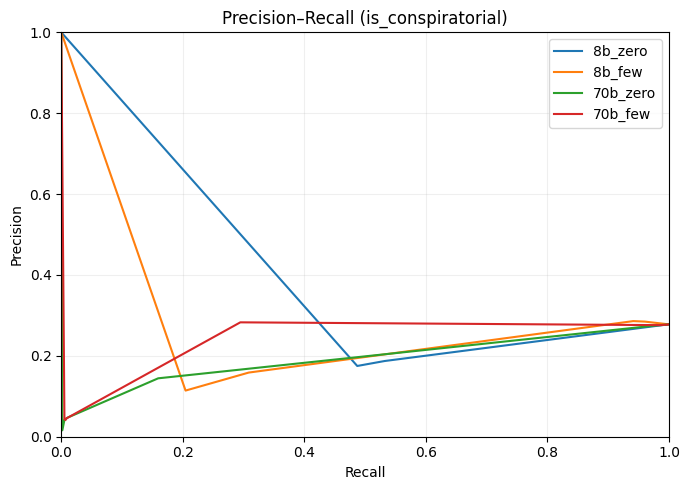

,experiment,AUPRC,n
3,70b_few,0.275925,2077
2,70b_zero,0.253314,2077
1,8b_few,0.236743,2077
0,8b_zero,0.223603,2077


In [44]:
# Analysis 11: Precision–Recall curves and AUPRC (is_conspiratorial)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, average_precision_score
from pathlib import Path

# Build per-model score/label vectors by joining with human MV
curves = {}
auprc_rows = []
for name, df in experiments.items():
    if 'text_id' not in df.columns:
        continue
    # prefer llm_confidence; fallback to confidence
    score_col = 'llm_confidence' if 'llm_confidence' in df.columns else ('confidence' if 'confidence' in df.columns else None)
    if score_col is None:
        # try to read from outputs raw if available
        p = Path(str(model_files.get(name,''))) if 'model_files' in globals() else None
        if p and p.exists():
            raw = pd.read_csv(p)
            if 'confidence' in raw.columns:
                df = df.merge(raw[['text_id','confidence']], on='text_id', how='left', suffixes=('', '_raw'))
                score_col = 'confidence'
    if score_col is None:
        continue
    if 'agg' not in globals() or agg is None or 'conspiracy_mv' not in agg.columns:
        continue
    j = df[['text_id', score_col, 'is_conspiratorial']].merge(agg[['text_id','conspiracy_mv']], on='text_id', how='inner')
    y_true = j['conspiracy_mv'].astype(bool).astype(int).values
    scores = pd.to_numeric(j[score_col], errors='coerce').clip(0,1).fillna(0.0).values
    if len(scores)==0:
        continue
    prec, rec, thr = precision_recall_curve(y_true, scores)
    auprc = average_precision_score(y_true, scores)
    curves[name] = (rec, prec)
    auprc_rows.append({'experiment': name, 'AUPRC': float(auprc), 'n': int(len(scores))})

if curves:
    plt.figure(figsize=(7,5))
    for name, (rec, prec) in curves.items():
        plt.plot(rec, prec, label=f"{name}")
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision–Recall (is_conspiratorial)')
    plt.xlim(0,1); plt.ylim(0,1); plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout(); plt.show()
    auprc_df = pd.DataFrame(auprc_rows).sort_values('AUPRC', ascending=False)
    display(auprc_df)
else:
    print('No curves available (missing confidence or labels).')


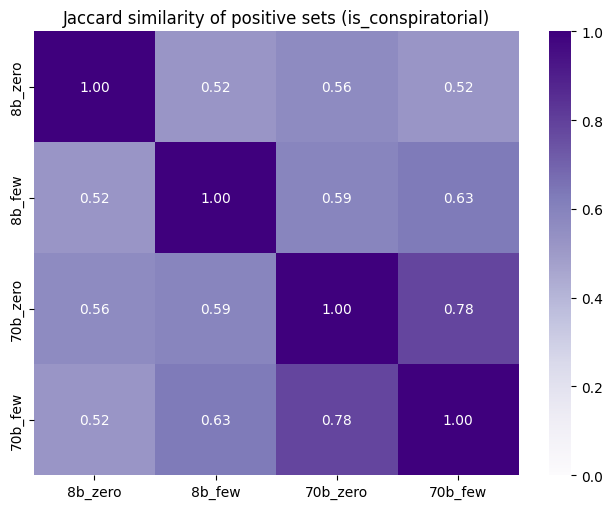

In [45]:
# Analysis 12: Jaccard similarity of positive sets (is_conspiratorial)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pos_sets = {}
for name, df in experiments.items():
    if {'text_id','is_conspiratorial'} <= set(df.columns):
        s = set(df[df['is_conspiratorial'].astype(bool)]['text_id'].tolist())
        if s:
            pos_sets[name] = s

names = list(pos_sets.keys())
if len(names) >= 2:
    n = len(names)
    jac = np.zeros((n,n), dtype=float)
    for i,a in enumerate(names):
        for j,b in enumerate(names):
            A, B = pos_sets[a], pos_sets[b]
            inter = len(A & B); union = len(A | B)
            jac[i,j] = inter/union if union>0 else np.nan
    plt.figure(figsize=(5+0.4*n,4+0.3*n))
    sns.heatmap(pd.DataFrame(jac, index=names, columns=names), annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1)
    plt.title('Jaccard similarity of positive sets (is_conspiratorial)')
    plt.tight_layout(); plt.show()
else:
    print('Not enough models with positives to compute similarity.')


Parsed runtimes (robust):


/tmp/ipykernel_2207143/2693391390.py:19: FutureWarning: Parsing 'CET' as tzlocal (dependent on system timezone) is deprecated and will raise in a future version. Pass the 'tz' keyword or call tz_localize after construction instead
  t_start = pd.to_datetime(m_start.group(1)) if m_start else None
/tmp/ipykernel_2207143/2693391390.py:20: FutureWarning: Parsing 'CET' as tzlocal (dependent on system timezone) is deprecated and will raise in a future version. Pass the 'tz' keyword or call tz_localize after construction instead
  t_end = pd.to_datetime(m_end.group(1)) if m_end else None


,log,label,start,end,duration_min,samples,throughput_smpm
0,annotate_70b_fewshot_transformers_8378699.out,70b_few,2025-11-02 23:00:49+01:00,2025-11-03 09:05:02+01:00,604.216667,2077.0,3.437509
1,annotate_70b_zeroshot_8333690.out,70b_zero,2025-11-02 05:32:13+01:00,NaT,NaN,NaN,NaN
2,annotate_70b_zeroshot_8333739.out,70b_zero,2025-11-02 05:35:32+01:00,NaT,NaN,2077.0,NaN
3,annotate_70b_zeroshot_8333986.out,70b_zero,2025-11-02 05:43:03+01:00,NaT,NaN,NaN,NaN
4,annotate_70b_zeroshot_8334057.out,70b_zero,2025-11-02 05:45:06+01:00,2025-11-02 15:01:29+01:00,556.383333,2077.0,3.733038
5,annotate_8b_8270900.out,8b,2025-10-31 22:10:02+01:00,2025-10-31 22:10:58+01:00,0.933333,10.0,10.714286
6,annotate_8b_8271043.out,8b,2025-10-31 22:14:24+01:00,2025-11-01 00:04:16+01:00,109.866667,3243.0,29.517597
7,annotate_8b_8276560.out,8b,2025-11-01 01:03:29+01:00,2025-11-01 02:14:59+01:00,71.500000,2077.0,29.048951
8,annotate_8b_8295982.out,8b,2025-11-01 10:44:09+01:00,2025-11-01 10:45:05+01:00,0.933333,10.0,10.714286
9,annotate_8b_8298993.out,8b,2025-11-01 12:13:05+01:00,2025-11-01 13:24:58+01:00,71.883333,2077.0,28.894041


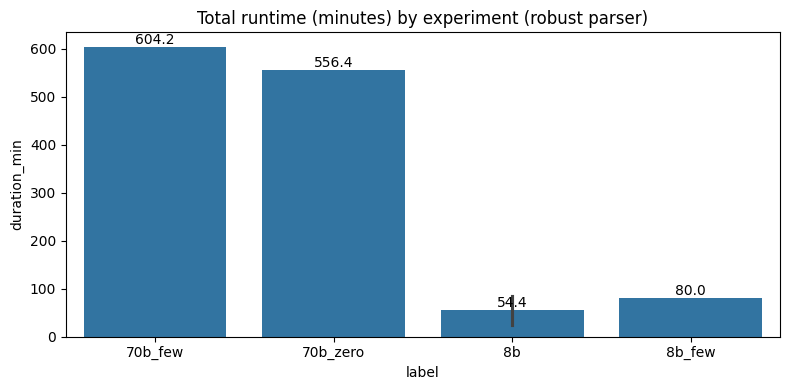

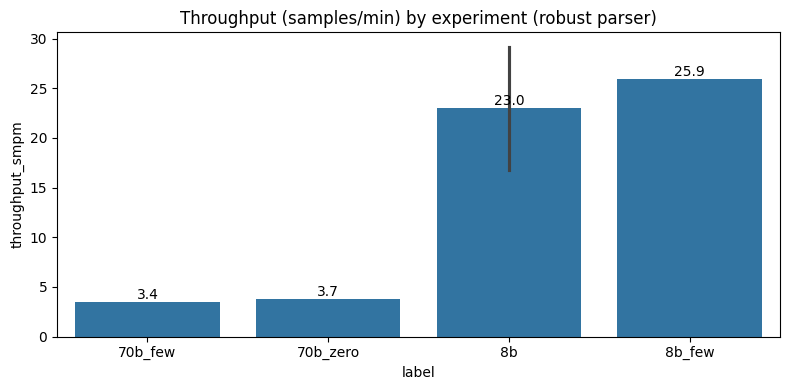

In [48]:
# Analysis 13b: Runtime (robust label detection incl. "zeroshot"/"zero-shot")
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

LOGS = Path('/home/ashrafs/projects/Conspiracy-Proj/logs')
rows = []
if LOGS.exists():
    for p in sorted(LOGS.glob('*.out')):
        try:
            txt = p.read_text(errors='ignore')
        except Exception:
            continue
        m_start = re.search(r'Job started at: (.+)', txt)
        m_end = re.search(r'Job finished at: (.+)', txt)
        t_start = pd.to_datetime(m_start.group(1)) if m_start else None
        t_end = pd.to_datetime(m_end.group(1)) if m_end else None
        duration_sec = (t_end - t_start).total_seconds() if (t_start is not None and t_end is not None) else np.nan
        m_proc = re.search(r'Processing\s+(\d+)\s+samples', txt)
        n_samples = int(m_proc.group(1)) if m_proc else np.nan
        blob = (p.name + ' ' + txt[:500]).lower()
        size = '70b' if '70b' in blob else ('8b' if '8b' in blob else '')
        shot = ''
        if re.search(r'(few( |-)?shot|\bfew\b)', blob):
            shot = 'few'
        elif re.search(r'(zero( |-)?shot|zeroshot|\bzero\b)', blob):
            shot = 'zero'
        label = f'{size}_{shot}' if size and shot else (size or shot or p.stem)
        rows.append({'log': p.name, 'label': label, 'start': t_start, 'end': t_end, 'duration_min': duration_sec/60 if pd.notna(duration_sec) else np.nan, 'samples': n_samples, 'throughput_smpm': (n_samples/(duration_sec/60)) if (pd.notna(duration_sec) and pd.notna(n_samples) and duration_sec>0) else np.nan})
else:
    print('Logs directory not found:', LOGS)

rt = pd.DataFrame(rows)
print('Parsed runtimes (robust):')
display(rt)

if not rt.empty:
    # show all labels including NaN durations
    plt.figure(figsize=(8,4))
    ax = sns.barplot(data=rt, x='label', y='duration_min')
    ax.set_title('Total runtime (minutes) by experiment (robust parser)')
    for c in ax.containers:
        try:
            ax.bar_label(c, fmt='%.1f')
        except Exception:
            pass
    plt.tight_layout(); plt.show()

    if rt['throughput_smpm'].notna().any():
        plt.figure(figsize=(8,4))
        ax = sns.barplot(data=rt, x='label', y='throughput_smpm')
        ax.set_title('Throughput (samples/min) by experiment (robust parser)')
        for c in ax.containers:
            try:
                ax.bar_label(c, fmt='%.1f')
            except Exception:
                pass
        plt.tight_layout(); plt.show()
else:
    print('No logs parsed.')


8b_zero  is_conspiratorial    left(human)=2043, right(model)=2077, merged=2077
8b_zero  supports_conspiracy  left(human)=2044, right(model)=2077, merged=2077
8b_few   is_conspiratorial    left(human)=2043, right(model)=2077, merged=2077
8b_few   supports_conspiracy  left(human)=2044, right(model)=2077, merged=2077
70b_zero is_conspiratorial    left(human)=2043, right(model)=2077, merged=2077
70b_zero supports_conspiracy  left(human)=2044, right(model)=2077, merged=2077
70b_few  is_conspiratorial    left(human)=2043, right(model)=2077, merged=2077
70b_few  supports_conspiracy  left(human)=2044, right(model)=2077, merged=2077


/tmp/ipykernel_3963564/548443804.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  left[task_gt] = left[task_gt].fillna(False).astype(bool)
/tmp/ipykernel_3963564/548443804.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  left[task_gt] = left[task_gt].fillna(False).astype(bool)
/tmp/ipykernel_3963564/548443804.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.n

,experiment,task,accuracy,precision,recall,f1,n
6,70b_few,is_conspiratorial,0.767453,0.542135,0.710866,0.615139,2077
4,70b_zero,is_conspiratorial,0.788156,0.579845,0.688766,0.629630,2077
2,8b_few,is_conspiratorial,0.733751,0.493455,0.694291,0.576894,2077
0,8b_zero,is_conspiratorial,0.791045,0.622472,0.510129,0.560729,2077
7,70b_few,supports_conspiracy,0.480982,0.681004,0.161154,0.260631,2077
5,70b_zero,supports_conspiracy,0.458353,0.725000,0.073791,0.133949,2077
3,8b_few,supports_conspiracy,0.464131,0.698795,0.098388,0.172491,2077
1,8b_zero,supports_conspiracy,0.432836,1.000000,0.000848,0.001695,2077


/tmp/ipykernel_3963564/548443804.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  left[task_gt] = left[task_gt].fillna(False).astype(bool)
/tmp/ipykernel_3963564/548443804.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  left[task_gt] = left[task_gt].fillna(False).astype(bool)


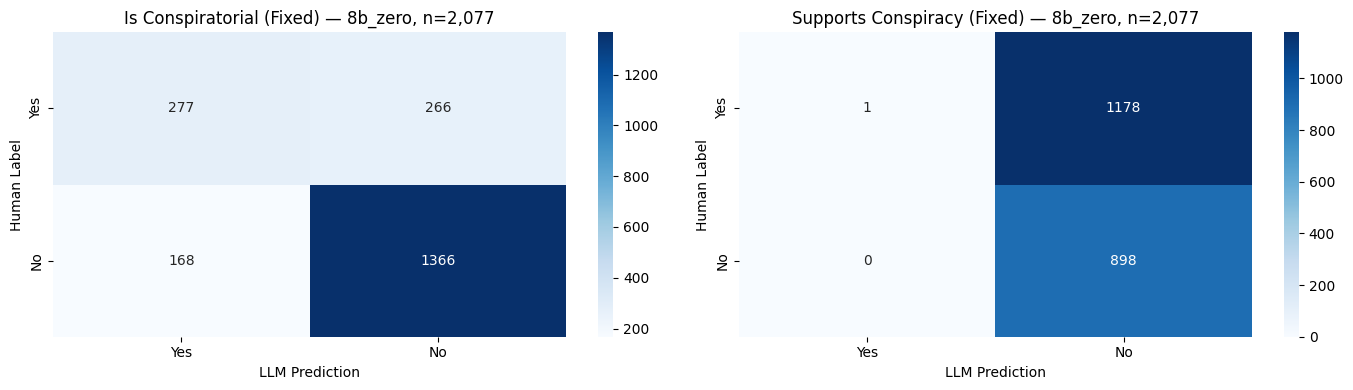